# Parte III — Rotação: Torque e Momento Angular

**Física I — Engenharia Naval, Poli-USP**

Material de estudo e revisão visual. Aqui não há exercícios para resolver — a ideia é
construir intuição física sobre rotação de corpos rígidos através de gráficos, animações
e deduções visuais, complementando a teoria vista em aula.

## Sumário

1. [Momento de inércia: sistemas discretos e contínuos](#1)
2. [Torque, aceleração angular e velocidade angular](#2)
3. [Momento angular, conservação e aplicações](#3)
4. [Rolamento sem escorregamento](#4)

---

> **Convenção**: ao longo do notebook, $\omega$ é a velocidade angular, $\alpha$ a aceleração
> angular, $I$ o momento de inércia e $L$ o momento angular. Vetores são escritos em negrito
> ($\vec{v}$) e seus módulos sem seta.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import sympy as sp

plt.rcParams.update({
    'figure.figsize': (8, 5),
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
    'axes.axisbelow': True,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'font.size': 11,
    'lines.linewidth': 2.2,
    'legend.frameon': False,
})

# paleta de cores consistente
CORES = {
    'azul':   '#2563eb',
    'laranja':'#f97316',
    'verde':  '#16a34a',
    'vermelho':'#dc2626',
    'roxo':   '#7c3aed',
    'cinza':  '#6b7280',
    'dourado':'#ca8a04',
}
PALETA = list(CORES.values())
print('Setup concluído. Paleta:', list(CORES.keys()))


Setup concluído. Paleta: ['azul', 'laranja', 'verde', 'vermelho', 'roxo', 'cinza', 'dourado']


<a id="1"></a>
## 1. Momento de inércia: sistemas discretos e contínuos

O momento de inércia $I$ mede a "resistência" de um corpo a mudanças em sua velocidade
angular — é o análogo rotacional da massa inercial.

### 1.1 Sistema discreto

Para um conjunto de massas pontuais $m_i$ a distâncias $r_i$ de um eixo de rotação:

$$I = \sum_i m_i r_i^2$$

Note o papel crucial da distância: ela entra **ao quadrado**. Massas duas vezes mais longe
contribuem **quatro vezes mais** para $I$.


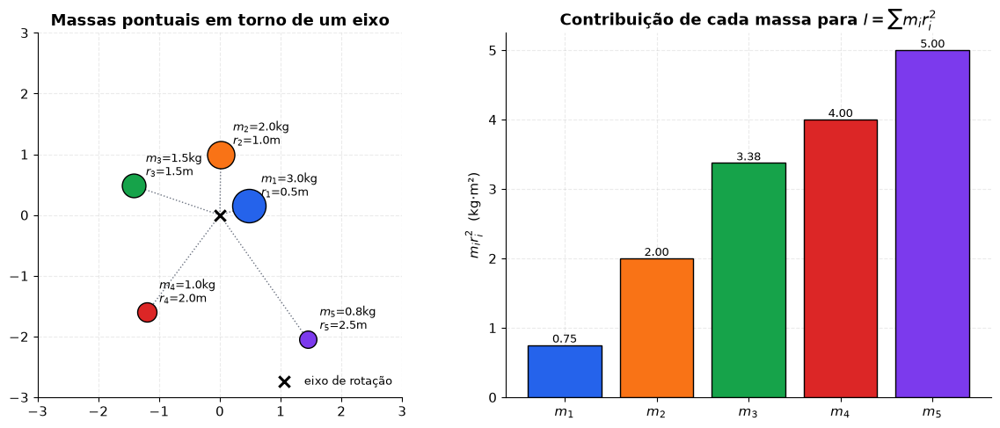

Momento de inércia total do sistema: I = 15.125 kg·m²


In [2]:

# Sistema discreto: massas pontuais a diferentes raios do eixo
raios = np.array([0.5, 1.0, 1.5, 2.0, 2.5])
massas = np.array([3.0, 2.0, 1.5, 1.0, 0.8])  # kg
contrib = massas * raios**2

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Painel esquerdo: vista "de cima" do eixo com as massas
ax = axs[0]
angles = np.linspace(0, 2*np.pi, len(raios), endpoint=False) + 0.3
for i, (r, m, ang) in enumerate(zip(raios, massas, angles)):
    x, y = r*np.cos(ang), r*np.sin(ang)
    ax.plot([0, x], [0, y], color=CORES['cinza'], lw=1, ls=':')
    ax.scatter(x, y, s=m*250, color=PALETA[i % len(PALETA)], edgecolor='k', zorder=3)
    ax.annotate(f'$m_{i+1}$={m}kg\n$r_{i+1}$={r}m', (x, y), textcoords='offset points',
                xytext=(10, 8), fontsize=9)
ax.scatter(0, 0, marker='x', color='k', s=80, zorder=4, label='eixo de rotação')
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_aspect('equal')
ax.set_title('Massas pontuais em torno de um eixo')
ax.legend(loc='lower right', fontsize=9)

# Painel direito: contribuição de cada massa para I
ax = axs[1]
bars = ax.bar([f'$m_{i+1}$' for i in range(len(raios))], contrib,
              color=PALETA[:len(raios)], edgecolor='k')
for b, v in zip(bars, contrib):
    ax.text(b.get_x()+b.get_width()/2, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel(r'$m_i r_i^2$  (kg·m²)')
ax.set_title(r'Contribuição de cada massa para $I=\sum m_i r_i^2$')

plt.tight_layout()
plt.show()

I_total = contrib.sum()
print(f"Momento de inércia total do sistema: I = {I_total:.3f} kg·m²")


> **Intuição física**: mesmo a massa mais leve do desenho acima ($m_5=0.8$ kg) pode
> contribuir quase tanto quanto a mais pesada ($m_1=3$ kg) para o momento de inércia, só
> porque está mais longe do eixo. É por isso que, em patinação, remar ou girar um taco de
> beisebol, *onde* a massa está importa tanto quanto *quanto* de massa existe.

### 1.2 Sistema contínuo: $I = \int r^2\,dm$

Para um corpo contínuo, trocamos a soma por uma integral sobre elementos de massa $dm$.
Vamos deduzir simbolicamente, com `sympy`, dois resultados clássicos.

**Barra fina em torno do centro:** dividimos a barra de comprimento $L$ e massa $M$ em
fatias de massa $dm = (M/L)\,dx$, a uma distância $x$ do centro:


In [3]:

x, L, M, R, rho = sp.symbols('x L M R rho', positive=True)

# Barra fina em torno do centro de massa
dm_barra = (M/L)
I_barra = sp.integrate(x**2 * dm_barra, (x, -L/2, L/2))
print("Barra fina (eixo no centro):  I =", sp.simplify(I_barra))


Barra fina (eixo no centro):  I = L**2*M/12


In [4]:

r = sp.symbols('r', positive=True)
# Disco em torno do eixo central: anéis de raio r, espessura dr, dm = (2*pi*r*dr)*sigma
sigma = M/(sp.pi*R**2)   # densidade superficial
dm_disco = 2*sp.pi*r*sigma
I_disco = sp.integrate(r**2 * dm_disco, (r, 0, R))
print("Disco (eixo central):  I =", sp.simplify(I_disco))


Disco (eixo central):  I = M*R**2/2


Os dois resultados simbólicos confirmam as fórmulas conhecidas:

$$I_{\text{barra, centro}} = \frac{1}{12}ML^2 \qquad\qquad I_{\text{disco}} = \frac{1}{2}MR^2$$

Visualizando a integração: fatiamos cada objeto em elementos coloridos pela sua
contribuição $r^2\,dm$ — quanto mais distante do eixo (cor mais quente), maior o peso na
integral.

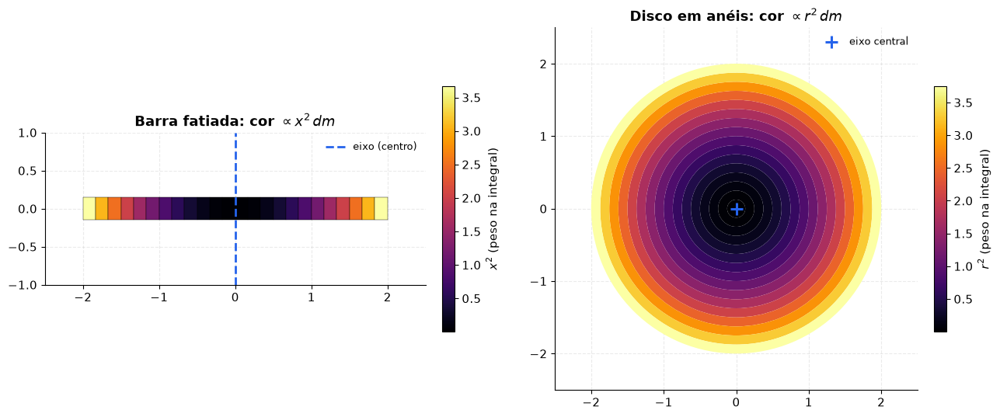

In [5]:

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Barra fatiada ---
ax = axs[0]
Lval = 4.0
n = 24
xs = np.linspace(-Lval/2, Lval/2, n+1)
centers = 0.5*(xs[:-1]+xs[1:])
contrib_barra = centers**2
cmap = plt.cm.inferno
norm = plt.Normalize(contrib_barra.min(), contrib_barra.max())
for i, c in enumerate(centers):
    ax.add_patch(mpatches.Rectangle((xs[i], -0.15), xs[i+1]-xs[i], 0.3,
                                     color=cmap(norm(contrib_barra[i])), ec='k', lw=0.3))
ax.axvline(0, color=CORES['azul'], lw=2, ls='--', label='eixo (centro)')
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-1, 1)
ax.set_aspect('equal')
ax.set_title(r'Barra fatiada: cor $\propto x^2\,dm$')
ax.legend(loc='upper right', fontsize=9)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
plt.colorbar(sm, ax=ax, fraction=0.03, pad=0.04, label=r'$x^2$ (peso na integral)')

# --- Disco em anéis ---
ax = axs[1]
Rval = 2.0
nrings = 16
redges = np.linspace(0, Rval, nrings+1)
rcenters = 0.5*(redges[:-1]+redges[1:])
contrib_disco = rcenters**2
norm2 = plt.Normalize(contrib_disco.min(), contrib_disco.max())
for i in range(nrings):
    ax.add_patch(mpatches.Annulus((0, 0), redges[i+1], redges[i+1]-redges[i],
                                   color=cmap(norm2(contrib_disco[i])), ec=None))
ax.scatter(0, 0, color=CORES['azul'], marker='+', s=120, zorder=5, label='eixo central')
ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
ax.set_aspect('equal')
ax.set_title(r'Disco em anéis: cor $\propto r^2\,dm$')
ax.legend(loc='upper right', fontsize=9)
sm2 = plt.cm.ScalarMappable(cmap=cmap, norm=norm2)
plt.colorbar(sm2, ax=ax, fraction=0.03, pad=0.04, label=r'$r^2$ (peso na integral)')

plt.tight_layout()
plt.show()


### 1.3 Teorema dos eixos paralelos (Steiner)

Se conhecemos $I_{cm}$ (momento de inércia em torno de um eixo que passa pelo centro de
massa), o momento de inércia em torno de qualquer eixo **paralelo**, a uma distância $d$, é:

$$I = I_{cm} + Md^2$$

O termo extra cresce quadraticamente com $d$ — afastar o eixo do CM sempre aumenta $I$.

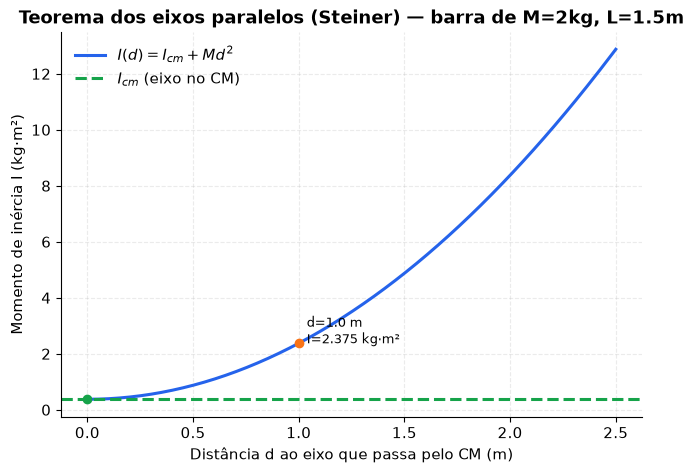

In [6]:

Mval, Lval = 2.0, 1.5   # kg, m
Icm = (1/12)*Mval*Lval**2
d = np.linspace(0, 2.5, 200)
I_d = Icm + Mval*d**2

plt.figure(figsize=(7.5,5))
plt.plot(d, I_d, color=CORES['azul'], label=r'$I(d) = I_{cm} + Md^2$')
plt.axhline(Icm, color=CORES['verde'], ls='--', label=r'$I_{cm}$ (eixo no CM)')
plt.scatter([0], [Icm], color=CORES['verde'], zorder=5)
dstar = 1.0
plt.scatter([dstar], [Icm+Mval*dstar**2], color=CORES['laranja'], zorder=5)
plt.annotate(f'  d={dstar} m\n  I={Icm+Mval*dstar**2:.3f} kg·m²',
             (dstar, Icm+Mval*dstar**2), fontsize=9)
plt.xlabel('Distância d ao eixo que passa pelo CM (m)')
plt.ylabel('Momento de inércia I (kg·m²)')
plt.title('Teorema dos eixos paralelos (Steiner) — barra de M=2kg, L=1.5m')
plt.legend()
plt.show()


> **Intuição física**: é sempre mais fácil girar um corpo em torno de um eixo que passa
> pelo seu centro de massa. Qualquer outro eixo paralelo "pune" o sistema com o termo
> $Md^2$ — por isso um taco de beisebol gira mais facilmente em torno do seu CM do que em
> torno de uma das extremidades.

### 1.4 Comparando formas geométricas

Para a mesma massa $M$ e mesmo raio $R$, a forma como a massa está distribuída muda
drasticamente o momento de inércia.

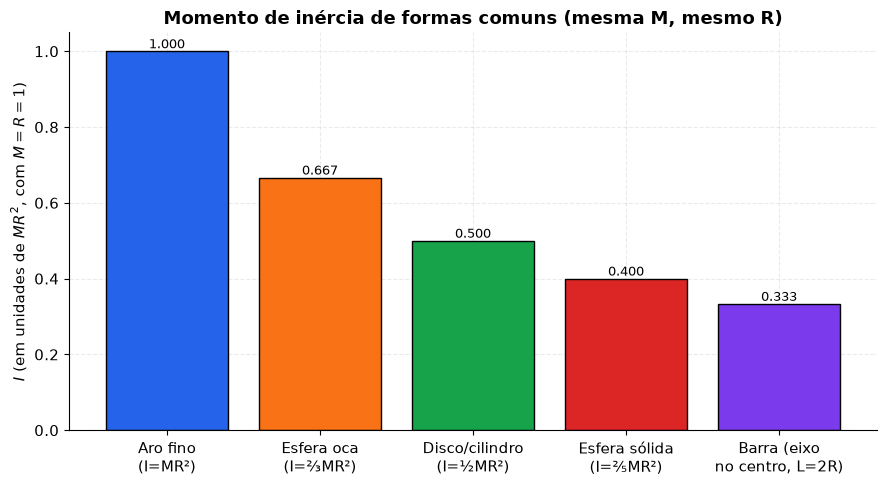

In [7]:

formas = ['Aro fino\n(I=MR²)', 'Esfera oca\n(I=⅔MR²)', 'Disco/cilindro\n(I=½MR²)',
          'Esfera sólida\n(I=⅖MR²)', 'Barra (eixo\nno centro, L=2R)']
Mv, Rv = 1.0, 1.0
valores = [Mv*Rv**2, (2/3)*Mv*Rv**2, 0.5*Mv*Rv**2, (2/5)*Mv*Rv**2, (1/12)*Mv*(2*Rv)**2]

plt.figure(figsize=(9,5))
bars = plt.bar(formas, valores, color=PALETA[:len(formas)], edgecolor='k')
for b, v in zip(bars, valores):
    plt.text(b.get_x()+b.get_width()/2, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
plt.ylabel(r'$I$ (em unidades de $MR^2$, com $M=R=1$)')
plt.title('Momento de inércia de formas comuns (mesma M, mesmo R)')
plt.tight_layout()
plt.show()


> **Intuição física**: o aro tem toda sua massa concentrada na borda ($I=MR^2$, o maior
> valor), enquanto a esfera sólida tem massa distribuída até o centro, inclusive bem perto
> do eixo ($I=\tfrac25MR^2$, o menor valor). Quanto mais concentrada a massa longe do eixo,
> maior o $I$ — isso será decisivo na "corrida de rolamento" da Seção 4.

<a id="2"></a>
## 2. Torque, aceleração angular e velocidade angular

### 2.1 Torque

O torque de uma força $\vec F$ aplicada num ponto a posição $\vec r$ relativa ao eixo é

$$\vec\tau = \vec r \times \vec F, \qquad \tau = rF\sin\theta$$

onde $\theta$ é o ângulo entre $\vec r$ e $\vec F$. O termo $r\sin\theta$ é o **braço de
alavanca** — a distância perpendicular entre a linha de ação da força e o eixo.

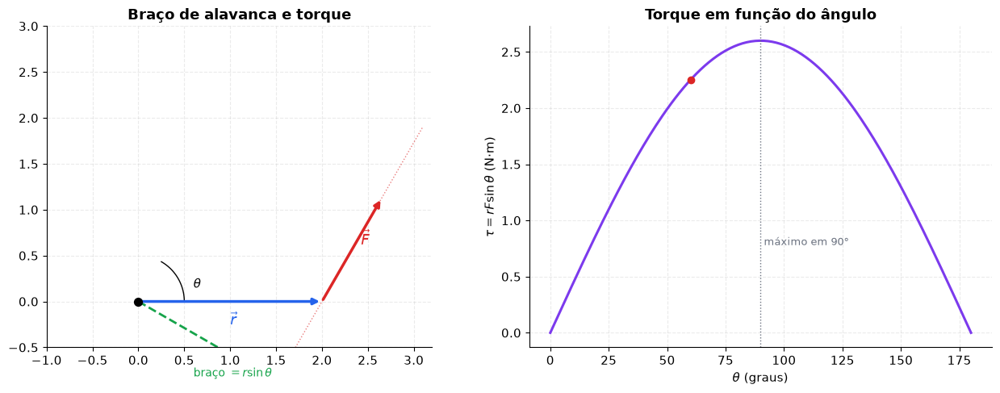

In [8]:

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# Diagrama do braço de alavanca
ax = axs[0]
r_vec = np.array([2.0, 0.0])
theta_graus = 60
theta = np.radians(theta_graus)
F_mag = 1.3
F_vec = F_mag*np.array([np.cos(theta), np.sin(theta)])

ax.annotate('', xy=r_vec, xytext=(0,0), arrowprops=dict(arrowstyle='-|>', color=CORES['azul'], lw=2.5))
ax.text(*(r_vec/2+np.array([0,-0.25])), r'$\vec r$', color=CORES['azul'], fontsize=13)

ax.annotate('', xy=r_vec+F_vec, xytext=r_vec, arrowprops=dict(arrowstyle='-|>', color=CORES['vermelho'], lw=2.5))
ax.text(*(r_vec+F_vec/2+np.array([0.1,0.05])), r'$\vec F$', color=CORES['vermelho'], fontsize=13)

# linha de acao de F estendida
t_line = np.linspace(-1, 2.2, 10)
linha_F = r_vec[:,None] + np.outer(F_vec/np.linalg.norm(F_vec), t_line)
ax.plot(linha_F[0], linha_F[1], color=CORES['vermelho'], ls=':', lw=1, alpha=0.6)

# pé da perpendicular da origem a linha de acao de F
d = F_vec/np.linalg.norm(F_vec)
v = -r_vec
proj = np.dot(v, d)*d
pe = r_vec + proj
ax.plot([0, pe[0]], [0, pe[1]], color=CORES['verde'], lw=2, ls='--')
ax.text(pe[0]*0.4, pe[1]*0.6-0.3, r'braço $= r\sin\theta$', color=CORES['verde'], fontsize=10)

arc_theta = np.linspace(0, theta, 30)
ax.plot(0.5*np.cos(arc_theta), 0.5*np.sin(arc_theta), color='k', lw=1)
ax.text(0.6, 0.15, r'$\theta$', fontsize=11)

ax.scatter(0,0, color='k', s=50, zorder=5)
ax.set_xlim(-1, 3.2); ax.set_ylim(-0.5, 3)
ax.set_aspect('equal')
ax.set_title('Braço de alavanca e torque')

# tau vs theta
ax2 = axs[1]
th = np.linspace(0, np.pi, 200)
r0, F0 = 2.0, 1.3
tau = r0*F0*np.sin(th)
ax2.plot(np.degrees(th), tau, color=CORES['roxo'])
ax2.scatter([theta_graus], [r0*F0*np.sin(theta)], color=CORES['vermelho'], zorder=5)
ax2.axvline(90, color=CORES['cinza'], ls=':', lw=1)
ax2.text(90, tau.max()*0.3, ' máximo em 90°', fontsize=9, color=CORES['cinza'])
ax2.set_xlabel(r'$\theta$ (graus)')
ax2.set_ylabel(r'$\tau = rF\sin\theta$ (N·m)')
ax2.set_title('Torque em função do ângulo')

plt.tight_layout()
plt.show()


### 2.2 Segunda lei de Newton para rotação

$$\tau_{\text{líquido}} = I\alpha$$

é o análogo rotacional de $F=ma$. A correspondência entre grandezas lineares e angulares
é direta:

| Linear | Angular | Relação |
|---|---|---|
| posição $x$ | posição angular $\theta$ | $x = r\theta$ |
| velocidade $v$ | velocidade angular $\omega$ | $v = r\omega$ |
| aceleração $a$ | aceleração angular $\alpha$ | $a = r\alpha$ |
| força $F$ | torque $\tau$ | $\tau = rF\sin\theta$ |
| massa $m$ | momento de inércia $I$ | $I=\sum m_ir_i^2$ |
| $F = ma$ | $\tau = I\alpha$ | — |
| energia cinética $\tfrac12 mv^2$ | energia cinética $\tfrac12 I\omega^2$ | — |
| momento linear $p=mv$ | momento angular $L=I\omega$ | — |

### 2.3 Disco acelerando sob torque constante

Vamos animar um disco homogêneo ($I=\tfrac12MR^2$) submetido a um torque constante. Como
$\alpha=\tau/I$ é constante, $\omega(t) = \alpha t$ cresce linearmente.

In [9]:

M_disco, R_disco, tau0 = 1.0, 1.0, 0.6
I_disco_num = 0.5*M_disco*R_disco**2
alpha = tau0/I_disco_num

t_frames = np.linspace(0, 4, 90)
omega_t = alpha*t_frames
theta_t = 0.5*alpha*t_frames**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))

# disco girando
ax1.set_xlim(-1.5, 1.5); ax1.set_ylim(-1.5, 1.5)
ax1.set_aspect('equal'); ax1.set_xticks([]); ax1.set_yticks([])
ax1.set_title('Disco sob torque constante')
circ = plt.Circle((0,0), R_disco, fill=False, color=CORES['azul'], lw=2.5)
ax1.add_patch(circ)
marcador, = ax1.plot([], [], 'o', color=CORES['vermelho'], ms=10)
raio_linha, = ax1.plot([], [], color=CORES['vermelho'], lw=2)
txt1 = ax1.text(-1.4, 1.3, '', fontsize=10)

# "gauge" de velocidade angular: arco preenchido tipo medidor
ax2.set_xlim(-1.3, 1.3); ax2.set_ylim(-1.3, 1.3)
ax2.set_aspect('equal'); ax2.set_xticks([]); ax2.set_yticks([])
ax2.set_title(r'Medidor de $\omega(t)$')
omega_max = omega_t.max()*1.05
back_arc = mpatches.Wedge((0,0), 1.0, -30, 210, width=0.25, color='#e5e7eb')
ax2.add_patch(back_arc)
fwd_wedge = mpatches.Wedge((0,0), 1.0, -30, -30, width=0.25, color=CORES['verde'])
ax2.add_patch(fwd_wedge)
txt2 = ax2.text(0, -0.15, '', ha='center', fontsize=13, fontweight='bold')
ax2.text(0, 0.35, r'$\omega$ (rad/s)', ha='center', fontsize=10, color=CORES['cinza'])

def init():
    marcador.set_data([], [])
    raio_linha.set_data([], [])
    return marcador, raio_linha

def update(i):
    th = theta_t[i]
    x, y = R_disco*np.cos(th), R_disco*np.sin(th)
    marcador.set_data([x],[y])
    raio_linha.set_data([0,x],[0,y])
    txt1.set_text(f't = {t_frames[i]:.2f} s\n' + r'$\omega$ = ' + f'{omega_t[i]:.2f} rad/s\n' + r'$\tau$ = ' + f'{tau0} N·m (cte)')
    frac = omega_t[i]/omega_max
    ang_sweep = -30 + 240*frac
    fwd_wedge.set_theta1(-30); fwd_wedge.set_theta2(ang_sweep)
    txt2.set_text(f'{omega_t[i]:.2f}')
    return marcador, raio_linha, txt1, fwd_wedge, txt2

anim = FuncAnimation(fig, update, frames=len(t_frames), init_func=init, interval=50, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim.to_jshtml())


> **Intuição física**: assim como uma força constante produz aceleração constante (e
> velocidade crescendo linearmente no tempo), um torque constante produz $\alpha$ constante
> e $\omega$ cresce linearmente — o "medidor" acima sobe a taxa fixa, igual a um
> velocímetro de carro acelerando a aceleração constante.

<a id="3"></a>
## 3. Momento angular, conservação e aplicações

### 3.1 Definição

Para uma partícula, $\vec L = \vec r\times\vec p$. Para um corpo rígido girando em torno de
um eixo fixo, $L = I\omega$. A segunda lei de Newton rotacional na forma mais geral é

$$\vec\tau_{\text{ext}} = \frac{d\vec L}{dt}$$

Quando o torque externo resultante é nulo, $L$ se conserva — mesmo que $I$ e $\omega$
mudem individualmente, desde que $I\omega = $ constante.

### 3.2 A patinadora: recolhendo os braços

O exemplo clássico: uma patinadora gira com os braços abertos (I grande, $\omega$ pequeno)
e, ao recolher os braços (I menor), $\omega$ aumenta para manter $L=I\omega$ constante.
Modelamos os "braços" como duas massas pontuais que se aproximam do eixo central.

In [10]:

# Modelo: duas massas (braços) a raio r(t) + tronco com Icorpo fixo
m_braco = 0.5  # kg cada "braço" (x2)
I_corpo = 0.4  # kg*m^2, parte fixa (tronco/pernas)
L_total = 3.0  # kg*m^2/s, momento angular conservado

n = 150
t = np.linspace(0, 6, n)
# r(t): comeca em 0.9 m (bracos abertos), recolhe para 0.2 m entre t=2 e t=4
r_t = np.piecewise(t,
    [t < 2, (t>=2)&(t<4), t>=4],
    [0.9, lambda tt: 0.9 - (0.9-0.2)*(tt-2)/2, 0.2])

I_t = I_corpo + 2*m_braco*r_t**2
omega_t2 = L_total / I_t   # L constante => omega = L/I
L_check = I_t*omega_t2

fig = plt.figure(figsize=(13, 7))
gs = fig.add_gridspec(2, 3)
ax_fig = fig.add_subplot(gs[:,0])
ax_I = fig.add_subplot(gs[0,1])
ax_w = fig.add_subplot(gs[0,2])
ax_L = fig.add_subplot(gs[1,1:])

ax_fig.set_xlim(-1.2,1.2); ax_fig.set_ylim(-1.2,1.2)
ax_fig.set_aspect('equal'); ax_fig.set_xticks([]); ax_fig.set_yticks([])
ax_fig.set_title('Patinadora (vista de cima)')
tronco = plt.Circle((0,0), 0.15, color=CORES['cinza'])
ax_fig.add_patch(tronco)
braco1, = ax_fig.plot([], [], 'o-', color=CORES['vermelho'], lw=3, ms=10)
braco2, = ax_fig.plot([], [], 'o-', color=CORES['azul'], lw=3, ms=10)
txt_fig = ax_fig.text(-1.1, 1.05, '', fontsize=10)

for ax, data, color, ylabel, title in [
    (ax_I, I_t, CORES['verde'], r'$I$ (kg·m²)', r'$I(t)$ diminui'),
    (ax_w, omega_t2, CORES['laranja'], r'$\omega$ (rad/s)', r'$\omega(t)$ aumenta'),
]:
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, data.max()*1.1)
    ax.set_title(title); ax.set_ylabel(ylabel); ax.set_xlabel('t (s)')

line_I, = ax_I.plot([], [], color=CORES['verde'])
line_w, = ax_w.plot([], [], color=CORES['laranja'])

ax_L.set_xlim(0, t[-1]); ax_L.set_ylim(0, L_total*1.3)
ax_L.axhline(L_total, color='k', ls='--', lw=1, label=r'$L$ constante')
line_L, = ax_L.plot([], [], color=CORES['roxo'], lw=2.5, label=r'$L(t)=I(t)\omega(t)$')
ax_L.set_title('Conservação do momento angular')
ax_L.set_xlabel('t (s)'); ax_L.set_ylabel(r'$L$ (kg·m²/s)')
ax_L.legend(loc='lower right', fontsize=9)

phi = np.cumsum(omega_t2)*(t[1]-t[0])  # angulo acumulado

def update3(i):
    ang = phi[i]
    r = r_t[i]
    x1,y1 = r*np.cos(ang), r*np.sin(ang)
    x2,y2 = r*np.cos(ang+np.pi), r*np.sin(ang+np.pi)
    braco1.set_data([0,x1],[0,y1])
    braco2.set_data([0,x2],[0,y2])
    txt_fig.set_text(f't={t[i]:.1f}s\nr={r:.2f}m\nω={omega_t2[i]:.2f} rad/s')
    line_I.set_data(t[:i+1], I_t[:i+1])
    line_w.set_data(t[:i+1], omega_t2[:i+1])
    line_L.set_data(t[:i+1], L_check[:i+1])
    return braco1, braco2, line_I, line_w, line_L, txt_fig

anim3 = FuncAnimation(fig, update3, frames=n, interval=40, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim3.to_jshtml())


O painel inferior confirma: $L(t) = I(t)\,\omega(t)$ permanece **rigorosamente
constante** durante todo o movimento, mesmo enquanto $I$ cai e $\omega$ dispara.

> **Intuição física**: a patinadora não faz nenhuma força "mágica" para girar mais rápido —
> ela apenas redistribui sua própria massa mais perto do eixo. Como $L=I\omega$ é
> conservado (torque externo ≈ 0, desprezando atrito do gelo), reduzir $I$ obriga $\omega$ a
> aumentar.

### 3.3 Áreas iguais em tempos iguais (analogia com a 2ª Lei de Kepler)

Um corpo em órbita sob uma força central (como a gravidade) não sofre torque em relação ao
centro de força, logo seu momento angular $L = m r^2\dot\theta$ é conservado. Isso implica
que a **taxa de varredura de área** $dA/dt = \tfrac12 r^2\dot\theta = L/2m$ é constante —
a famosa 2ª Lei de Kepler, que é, no fundo, conservação de momento angular.

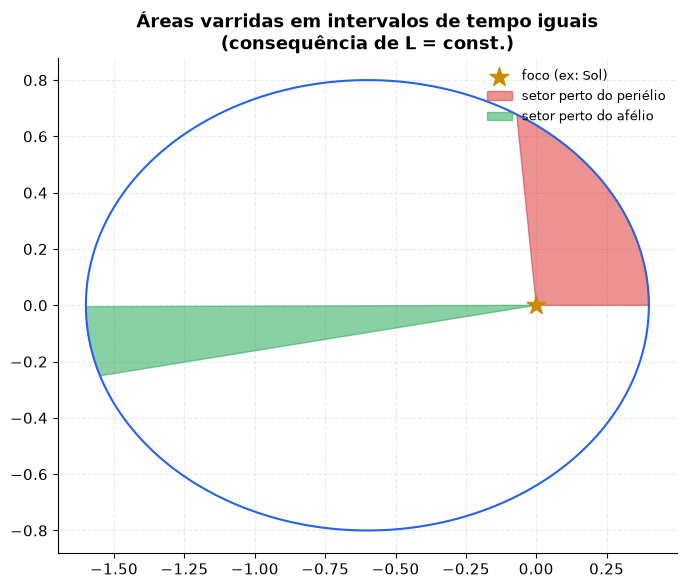

In [11]:

# Orbita eliptica simples (parametrizacao kepleriana simplificada)
a_orb, e_orb = 1.0, 0.6
theta_orb = np.linspace(0, 2*np.pi, 1000)
r_orb = a_orb*(1-e_orb**2)/(1+e_orb*np.cos(theta_orb))
x_orb, y_orb = r_orb*np.cos(theta_orb), r_orb*np.sin(theta_orb)

# Para L constante, dA/dt=cte -> usamos a 2a lei de Kepler numericamente: dt ~ r^2 dtheta
dtheta = np.diff(theta_orb)
r_mid = 0.5*(r_orb[:-1]+r_orb[1:])
dt_elem = r_mid**2 * dtheta
t_cum = np.concatenate([[0], np.cumsum(dt_elem)])
t_cum /= t_cum[-1]

def idx_for_time(t0, t1):
    i0 = np.searchsorted(t_cum, t0)
    i1 = np.searchsorted(t_cum, t1)
    return i0, i1

# dois intervalos de tempo iguais: um perto do perielio, outro longe (afelio)
i0a, i1a = idx_for_time(0.0, 0.08)
i0b, i1b = idx_for_time(0.5, 0.58)

fig, ax = plt.subplots(figsize=(7,7))
ax.plot(x_orb, y_orb, color=CORES['azul'], lw=1.5)
ax.scatter([0],[0], color=CORES['dourado'], s=200, marker='*', label='foco (ex: Sol)', zorder=5)

for (i0,i1), cor, label in [((i0a,i1a), CORES['vermelho'], 'setor perto do periélio'),
                              ((i0b,i1b), CORES['verde'], 'setor perto do afélio')]:
    xs = np.concatenate([[0], x_orb[i0:i1+1]])
    ys = np.concatenate([[0], y_orb[i0:i1+1]])
    ax.fill(xs, ys, color=cor, alpha=0.5, label=label)

ax.set_aspect('equal')
ax.set_title('Áreas varridas em intervalos de tempo iguais\n(consequência de L = const.)')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()


Mesmo com o setor vermelho (perto do foco) sendo muito mais "estreito em ângulo"
do que o verde, as duas áreas são praticamente iguais — porque correspondem ao mesmo
intervalo de tempo. Perto do periélio, $r$ é pequeno e, como $L=mr^2\dot\theta$ é
constante, $\dot\theta$ precisa ser grande para compensar.

> **Intuição física**: isso é exatamente o mesmo princípio da patinadora. Quando o corpo
> (planeta, cometa, ou um peso girando preso a uma corda que se enrola em um poste) se
> aproxima do centro, ele é obrigado a girar mais depressa para conservar $L$.

<a id="4"></a>
## 4. Rolamento sem escorregamento

### 4.1 A condição de rolamento e o campo de velocidades

Quando uma roda de raio $R$ rola sem escorregar, seu centro se move com velocidade
$v_{cm}=\omega R$. Isso é um ponto que costuma confundir: **nem todo ponto da roda tem essa
velocidade!** O campo de velocidades é a soma da translação do centro com a rotação em
torno do centro:

$$\vec v(\text{ponto}) = \vec v_{cm} + \vec\omega\times\vec r'$$

- No **ponto de contato com o chão**: a velocidade de rotação ($-v_{cm}$) cancela exatamente
  a translação ($+v_{cm}$) → **velocidade zero** (por isso não há escorregamento!).
- No **centro**: velocidade $v_{cm}$.
- No **topo**: as duas velocidades se somam → $2v_{cm}$.

In [12]:

Rroda = 1.0
vcm = 1.0
omega_roda = vcm/Rroda

n2 = 100
theta_c = np.linspace(0, 4*np.pi, n2)  # angulo de rotacao acumulado
xc = Rroda*theta_c  # posicao do centro (rolamento puro: x = R*theta)

fig, ax = plt.subplots(figsize=(11,5))
ax.set_xlim(-0.5, xc.max()+1.5)
ax.set_ylim(-0.3, 2.8)
ax.set_aspect('equal')
ax.axhline(0, color='k', lw=1)
ax.set_title('Roda rolando sem escorregar: campo de velocidades')
ax.set_xticks([]); ax.set_yticks([])

circulo = plt.Circle((xc[0], Rroda), Rroda, fill=False, color=CORES['azul'], lw=2.5)
ax.add_patch(circulo)
raio_marca, = ax.plot([], [], color=CORES['cinza'], lw=1.5)

v_topo = ax.annotate('', xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle='-|>', color=CORES['vermelho'], lw=2.5))
v_centro = ax.annotate('', xy=(0,0), xytext=(0,0), arrowprops=dict(arrowstyle='-|>', color=CORES['verde'], lw=2.5))
v_contato = ax.scatter([], [], color=CORES['laranja'], s=80, zorder=6)
txt4 = ax.text(0, 2.5, '', fontsize=10)

escala = 0.6
def update4(i):
    cx, cy = xc[i], Rroda
    circulo.center = (cx, cy)
    ang = theta_c[i]
    px, py = cx + Rroda*np.sin(ang), cy - Rroda*np.cos(ang)  # ponto marcado na borda (gira com a roda)
    raio_marca.set_data([cx, px],[cy, py])

    topo = (cx, 2*Rroda)
    centro = (cx, Rroda)
    contato = (cx, 0)

    v_topo.set_position(topo); v_topo.xy = (topo[0]+2*vcm*escala, topo[1])
    v_centro.set_position(centro); v_centro.xy = (centro[0]+vcm*escala, centro[1])
    v_contato.set_offsets([contato])

    ax.set_xlim(cx-3, cx+3)
    txt4.set_position((cx-2.8, 2.5))
    txt4.set_text(r'topo: $v=2v_{cm}$ (vermelho)   centro: $v=v_{cm}$ (verde)   contato: $v=0$ (laranja)')
    return circulo, raio_marca, v_topo, v_centro, v_contato, txt4

anim4 = FuncAnimation(fig, update4, frames=n2, interval=50, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim4.to_jshtml())


> **Intuição física — ponto-chave**: o ponto de contato com o chão tem velocidade
> **instantânea nula**. É justamente essa condição ($v=0$ no ponto de apoio) que define
> "rolar sem escorregar" — e é também por isso que o atrito estático (que não realiza
> trabalho porque o ponto de contato não desliza) pode manter o rolamento sem dissipar
> energia.

### 4.2 A cicloide: trajetória de um ponto na borda

Um ponto fixo na borda da roda não descreve um círculo (porque a roda também translada) —
ele traça uma **cicloide**:

$$x(\theta) = R(\theta - \sin\theta), \qquad y(\theta) = R(1-\cos\theta)$$

In [13]:

theta_cic = np.linspace(0, 4*np.pi, n2)
x_cic = Rroda*(theta_cic - np.sin(theta_cic))
y_cic = Rroda*(1 - np.cos(theta_cic))

fig, ax = plt.subplots(figsize=(11,4.5))
ax.set_xlim(-0.5, x_cic.max()+0.5)
ax.set_ylim(-0.3, 2.6)
ax.set_aspect('equal')
ax.axhline(0, color='k', lw=1)
ax.set_title('Cicloide: trajetória de um ponto na borda da roda')
ax.set_xticks([]); ax.set_yticks([])

trilha, = ax.plot([], [], color=CORES['roxo'], lw=2, label='trajetória (cicloide)')
circulo2 = plt.Circle((0, Rroda), Rroda, fill=False, color=CORES['azul'], lw=2)
ax.add_patch(circulo2)
ponto_borda, = ax.plot([], [], 'o', color=CORES['vermelho'], ms=10)
raio_linha2, = ax.plot([], [], color=CORES['cinza'], lw=1.2)
ax.legend(loc='upper left', fontsize=9)

def update5(i):
    cx = Rroda*theta_cic[i]
    circulo2.center = (cx, Rroda)
    px, py = x_cic[i], y_cic[i]
    ponto_borda.set_data([px],[py])
    raio_linha2.set_data([cx,px],[Rroda,py])
    trilha.set_data(x_cic[:i+1], y_cic[:i+1])
    ax.set_xlim(cx-3.2, cx+3.2)
    return trilha, circulo2, ponto_borda, raio_linha2

anim5 = FuncAnimation(fig, update5, frames=n2, interval=50, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim5.to_jshtml())


Note como a velocidade do ponto é zero exatamente quando ele toca o chão (a
cicloide tem uma "cúspide" ali) — consistente com o campo de velocidades da Seção 4.1.

### 4.3 Energia cinética de rolamento e a corrida de rolamento

A energia cinética total de um corpo rolando combina translação e rotação do CM:

$$K = \underbrace{\tfrac12 M v_{cm}^2}_{\text{translação}} + \underbrace{\tfrac12 I_{cm}\omega^2}_{\text{rotação}}$$

Descendo um plano inclinado de ângulo $\theta$ sem escorregar, a aceleração do centro de
massa é

$$a = \frac{g\sin\theta}{1 + I_{cm}/(MR^2)}$$

Quanto **maior** a fração $I_{cm}/(MR^2)$ (mais massa concentrada na borda), **menor** a
aceleração — o objeto "gasta" mais energia girando e menos translando.

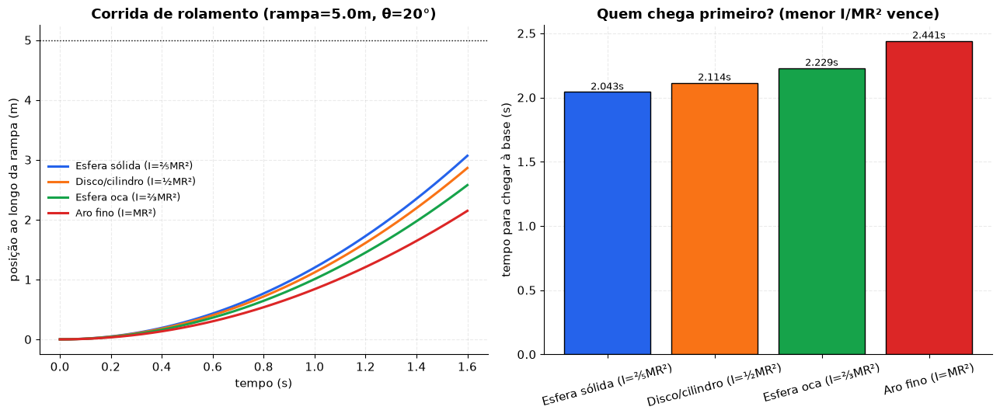

Ordem de chegada (do mais rápido ao mais lento):
  Esfera sólida (I=⅖MR²): 2.0427 s
  Disco/cilindro (I=½MR²): 2.1144 s
  Esfera oca (I=⅔MR²): 2.2288 s
  Aro fino (I=MR²): 2.4415 s


In [14]:

g = 9.81
theta_inc = np.radians(20)
objetos = {
    'Esfera sólida (I=⅖MR²)': 2/5,
    'Disco/cilindro (I=½MR²)': 1/2,
    'Esfera oca (I=⅔MR²)':   2/3,
    'Aro fino (I=MR²)':       1.0,
}
cores_obj = {k: PALETA[i] for i,k in enumerate(objetos)}

t_corrida = np.linspace(0, 1.6, 200)
Lrampa = 5.0  # m, comprimento da rampa

fig, axs = plt.subplots(1, 2, figsize=(13,5.5))
ax1, ax2 = axs

resultados = {}
for nome, k in objetos.items():
    a = g*np.sin(theta_inc)/(1+k)
    x_t = 0.5*a*t_corrida**2
    resultados[nome] = (a, x_t)
    ax1.plot(t_corrida, np.minimum(x_t, Lrampa), label=nome, color=cores_obj[nome])

ax1.axhline(Lrampa, color='k', ls=':', lw=1)
ax1.set_xlabel('tempo (s)'); ax1.set_ylabel('posição ao longo da rampa (m)')
ax1.set_title(f'Corrida de rolamento (rampa={Lrampa}m, θ=20°)')
ax1.legend(fontsize=9)

# tempo para chegar na base
nomes = list(objetos.keys())
tempos_chegada = [np.sqrt(2*Lrampa/a) for a,_ in resultados.values()]
bars = ax2.bar(nomes, tempos_chegada, color=[cores_obj[n] for n in nomes], edgecolor='k')
for b,v in zip(bars, tempos_chegada):
    ax2.text(b.get_x()+b.get_width()/2, v, f'{v:.3f}s', ha='center', va='bottom', fontsize=9)
ax2.set_ylabel('tempo para chegar à base (s)')
ax2.set_title('Quem chega primeiro? (menor I/MR² vence)')
ax2.tick_params(axis='x', labelrotation=15)

plt.tight_layout()
plt.show()

print("Ordem de chegada (do mais rápido ao mais lento):")
for nome, tempo in sorted(zip(nomes, tempos_chegada), key=lambda p: p[1]):
    print(f"  {nome}: {tempo:.4f} s")


In [15]:

# Pequena animação da corrida lado a lado
fig, ax = plt.subplots(figsize=(11,3.2))
ax.set_xlim(-0.3, Lrampa+0.3)
ax.set_ylim(0.5, len(objetos)+0.5)
ax.set_yticks(range(1, len(objetos)+1))
ax.set_yticklabels(nomes, fontsize=9)
ax.set_xlabel('posição na rampa (m)')
ax.set_title('Corrida de rolamento: esfera sólida vence!')
ax.axvline(Lrampa, color='k', ls=':', lw=1)

pontos = {}
for i, nome in enumerate(nomes):
    p, = ax.plot([], [], 'o', color=cores_obj[nome], ms=14)
    pontos[nome] = p

def update6(frame):
    tt = t_corrida[frame]
    for i, nome in enumerate(nomes):
        a,_ = resultados[nome]
        x = min(0.5*a*tt**2, Lrampa)
        pontos[nome].set_data([x],[i+1])
    return list(pontos.values())

anim6 = FuncAnimation(fig, update6, frames=len(t_corrida), interval=35, blit=False)
plt.tight_layout()
plt.close(fig)
HTML(anim6.to_jshtml())


> **Intuição física**: repare que o resultado **não depende de $M$ nem de $R$** — só da
> forma como a massa está distribuída (o fator $I_{cm}/MR^2$). Por isso uma bola de boliche
> grande e uma bolinha de gude pequena, ambas esferas sólidas uniformes, chegam **juntas**
> ao fim de uma rampa (na ausência de atrito de rolamento/resistência do ar), mas uma esfera
> sempre vence um aro idêntico em massa e raio — a esfera converte menos energia em rotação
> e mais em translação.

---

## Resumo visual da Parte III

| Conceito | Fórmula-chave |
|---|---|
| Momento de inércia (discreto) | $I=\sum m_ir_i^2$ |
| Momento de inércia (contínuo) | $I=\int r^2\,dm$ |
| Eixos paralelos (Steiner) | $I=I_{cm}+Md^2$ |
| Torque | $\vec\tau=\vec r\times\vec F$, $\ \tau=rF\sin\theta$ |
| 2ª lei de Newton rotacional | $\tau=I\alpha$ |
| Momento angular | $\vec L=\vec r\times\vec p$, $\ L=I\omega$ |
| Conservação de L | $\tau_{ext}=0 \Rightarrow L=$ cte |
| Rolamento sem escorregar | $v_{cm}=\omega R$ |
| Energia de rolamento | $K=\tfrac12Mv_{cm}^2+\tfrac12I_{cm}\omega^2$ |
| Aceleração na rampa | $a=\dfrac{g\sin\theta}{1+I_{cm}/MR^2}$ |

Bons estudos!